# 03 · A plant whose truth is known

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/EngMtaleb/chemai/blob/main/projects/p03_ro_fouling/notebooks/03_simulator.ipynb)

On a real plant, every cycle ends when the operator cleans. Nobody ever sees the day the train
*would* have reached the review level — so a forecast of that day cannot be scored on real data
alone. A simulator keeps the true fouling state, and can replay any day **without** the cleaning.

Script version: `projects/p03_ro_fouling/step3_simulator.py` · record: `VALIDATION.md`, section 8.

In [1]:
# Setup. In Google Colab this installs the package from GitHub (about a minute).
# On your own machine, run from a clone after:  pip install -e ".[viz]"
import os, subprocess, sys
REF = "main"        # before the Project 3 pull request is merged, use "p03-ro-fouling"
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    f"chemai[viz] @ git+https://github.com/EngMtaleb/chemai.git@{REF}"], check=True)
    os.environ["CHEMAI_DATA_DIR"] = "/content/data"     # where the deposit is downloaded

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140)
COL = {"A": "#2a6fb0", "B": "#128c84", "C": "#a8782f"}

## 1. Three plants, three fouling laws

Each plant: three trains, 770 days, seasonal temperature, production that steps as trains start
and stop, upsets, an operator who cleans on what the screen shows, a differential transmitter with
noise and outliers. Fouling grows by one of three laws: **linear** (steady deposition), **biofilm**
(accelerating, faster in warm water) or **asymptotic** (deposition balanced by removal).

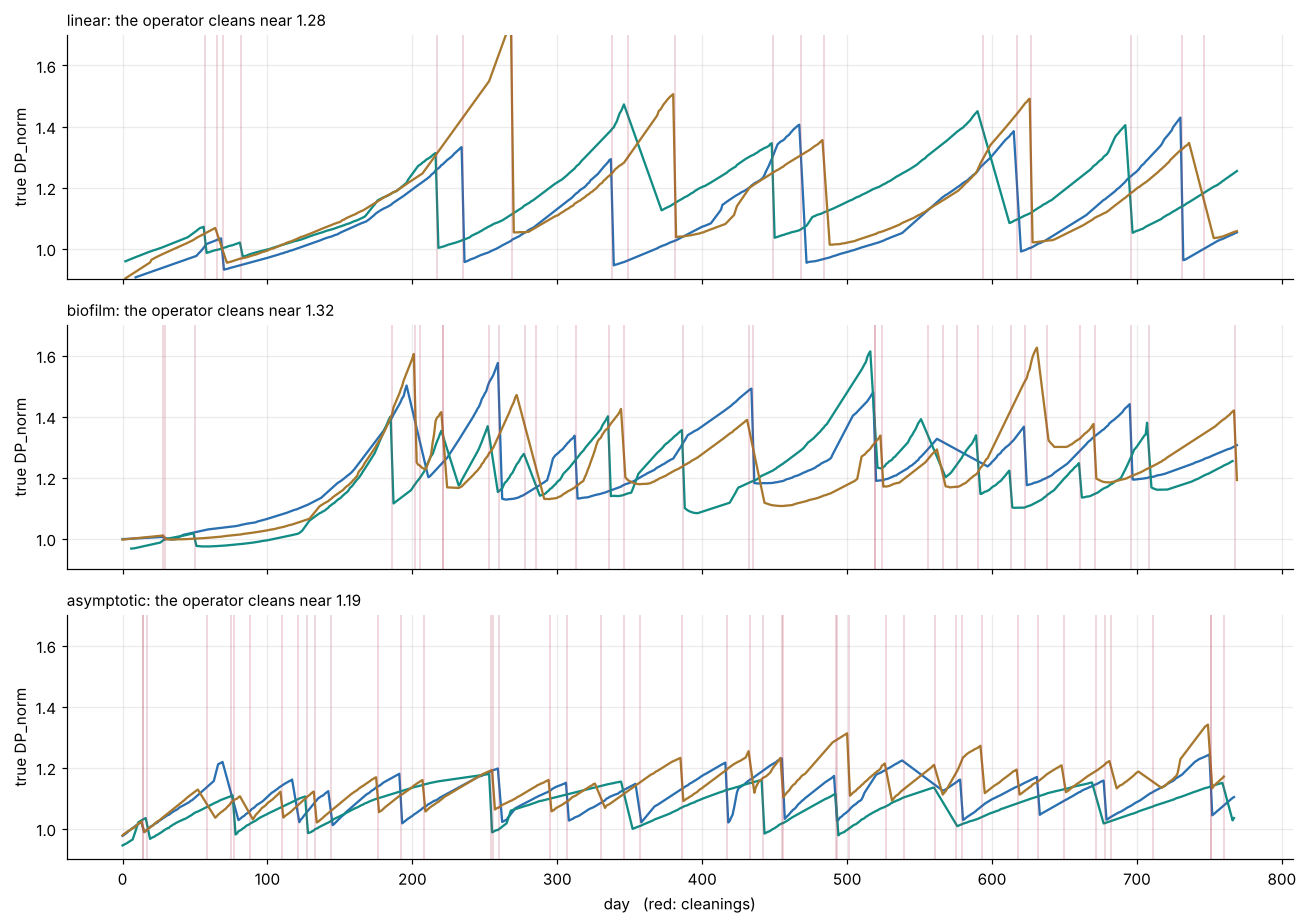

In [2]:
from chemai.config import ROSimConfig
from chemai.data.ro_sim import counterfactual, sample_plant, simulate_plant
from chemai.evaluation.fouling_eval import plant_view, sim_cycles

sim = ROSimConfig()
rng = np.random.default_rng(1)
plants = {law: simulate_plant(sample_plant(rng, sim, law), sim) for law in sim.laws}

fig, axes = plt.subplots(3, 1, figsize=(12, 8.5), sharex=True)
for ax, (law, run) in zip(axes, plants.items()):
    for tr in "ABC":
        g = run.daily[(run.daily["train"] == tr) & run.daily["recorded"]]
        ax.plot(g["day"], g["dp_true"], color=COL[tr], lw=1.5)
    for d in run.cleanings["day"]:
        ax.axvline(d, color="#b53c58", alpha=0.25, lw=1)
    ax.set_ylim(0.9, 1.7); ax.set_ylabel("true DP_norm")
    ax.set_title(f"{law}: the operator cleans near {run.params.operator_level:.2f}", loc="left", fontsize=10)
axes[-1].set_xlabel("day   (red: cleanings)")
plt.tight_layout(); plt.show()

In [3]:
plants["linear"].cleanings.head(8)    # every cleaning, with the reason the operator had

,train,day,legs,reason
0,B,57,1,time since last cleaning
1,C,65,1,time since last cleaning
2,A,69,1,time since last cleaning
3,B,82,1,other reason
4,B,217,2,other reason
5,A,235,1,dP on screen
6,C,269,1,time since last cleaning
7,A,338,2,dP on screen


## 2. The path that never happened

Take one cycle and ask, three weeks into it: had nobody cleaned, when would the train have reached
the review level (1.25 here)? The counterfactual uses the same temperatures, the same rate noise and the same upsets — only the
operator's decision is removed.

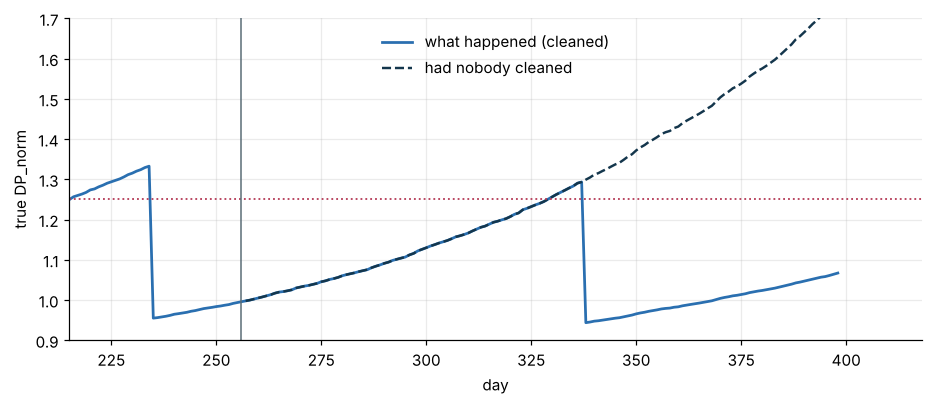

decision on day 256: had nobody cleaned, the train reaches 1.25 on day 329 (73 days later).
the operator cleaned on day 338 (dP on screen): the real record never shows that crossing.


In [4]:
run = plants["linear"]
cips = run.cleanings.loc[run.cleanings["train"] == "A", "day"].astype(int).sort_values().to_list()
start, end = cips[1], cips[2]                            # one cycle of train A
d0 = start + 21                                          # a decision three weeks into it
level = 1.25
path = counterfactual(run, "A", d0, 250)
g = run.daily[(run.daily["train"] == "A") & run.daily["day"].between(start - 20, end + 60)]
hit = int(np.argmax(path >= level)) + 1 if (path >= level).any() else None

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(g["day"], g["dp_true"], color=COL["A"], lw=1.8, label="what happened (cleaned)")
ax.plot(d0 + np.arange(1, 251), path, "--", color="#14364c", lw=1.6, label="had nobody cleaned")
ax.axhline(level, color="#b53c58", ls=":", lw=1.2); ax.axvline(d0, color="#5b6d77", lw=1)
ax.set_xlim(start - 20, end + 80); ax.set_ylim(0.9, 1.7); ax.set_xlabel("day"); ax.set_ylabel("true DP_norm"); ax.legend(frameon=False)
plt.show()
reason = run.cleanings.loc[(run.cleanings["train"] == "A") & (run.cleanings["day"] == end), "reason"].iloc[0]
print(f"decision on day {d0}: had nobody cleaned, the train reaches {level} " +
      (f"on day {d0 + hit} ({hit} days later)." if hit else "only after more than 250 days."))
print(f"the operator cleaned on day {end} ({reason}): the real record never shows that crossing.")

## 3. What the plant actually sees

The plant reads a noisy transmitter, normalises it, and — like the deposit — clips everything at
or below the start-up value to the baseline (censored).

In [5]:
v = plant_view(run, "fit")                 # normalised with the plant's own fitted exponent
print("censored share:", round(v["censored"].mean(), 3))
cyc = sim_cycles(run, 0, view=v)
print(len(cyc), "cycles;", sum(c.closed for c in cyc), "closed by a cleaning")
v.head()

censored share: 0.174
19 cycles; 16 closed by a cleaning


,train,day,running,recorded,phi,g,cip,n_on,temperature_c,true_temperature,...,feed_tds,perm_tds,dp,true_dp,true_feed_pressure,true_q_avg,dp_true,dp_norm_raw,censored,dp_norm_obs
0,A,9,True,True,0.026038,1.017483,False,2.0,29.632773,29.264763,...,33.951348,0.205378,1.342991,1.339030,50.179728,21.610334,0.906096,0.889485,True,1.000000
1,A,49,True,True,0.124511,1.092426,False,2.0,27.075464,26.955285,...,33.432437,0.199887,1.279972,1.261000,51.047601,19.870815,0.972835,0.968509,True,1.000000
2,A,50,True,True,0.127178,1.094684,False,2.0,26.976905,26.649206,...,33.808669,0.208507,1.255898,1.229524,50.696951,19.537627,0.974846,0.999946,True,1.000000
3,A,51,True,True,0.129041,1.096270,False,3.0,25.942014,26.079525,...,33.237924,0.257972,0.794240,0.794151,47.849386,15.125757,0.976258,0.992936,True,1.000000
4,A,53,True,True,0.142843,1.108232,False,2.0,25.452618,25.665292,...,33.699386,0.189017,1.342279,1.305704,51.045022,20.015998,0.986911,1.004942,False,1.004942


## 4. Does it look like the real plant?

The honest check: compare simulated cycles with the deposit's 15 complete cycles — length, slope,
and how much DP_norm jumps from one day to the next (the noise a forecast has to see through).

In [6]:
from scipy import stats
from chemai.config import RODepositConfig
from chemai.data.ro_deposit import download_deposit, load_daily, split_cycles
from chemai.data.ro_sim import generate_plants

def cycle_stats(cycles):
    out = []
    for c in cycles:
        m = (c.day > 3) & (c.day <= 45)                 # the first six weeks, as a forecast sees them
        if m.sum() < 8:
            continue
        d, x = c.day[m], c.dp_norm[m]
        slope = stats.theilslopes(x, d)[0] * 7
        dx = np.diff(x)[np.diff(d) == 1]
        jump = 1.4826 * np.median(np.abs(dx - np.median(dx))) / np.sqrt(2) if len(dx) >= 5 else np.nan
        out.append(dict(length=c.end - c.start, slope=slope, jump=jump))
    return pd.DataFrame(out)

dcfg = RODepositConfig()
real = [c for c in split_cycles(load_daily(download_deposit(cfg=dcfg) / dcfg.daily_file), dcfg) if c.kind == "complete"]
runs = generate_plants(15, seed=3003)
simc = [c for i, r in enumerate(runs) for c in sim_cycles(r, i) if c.closed]
R, S = cycle_stats(real), cycle_stats(simc)
cmp = pd.DataFrame({"deposit": R.median(), "simulator": S.median()})
cmp["simulator / deposit"] = (cmp["simulator"] / cmp["deposit"]).round(2)
print(len(R), "real cycles,", len(S), "simulated")
cmp.round(4)

15 real cycles, 245 simulated


,deposit,simulator,simulator / deposit
length,42.0000,120.0000,2.86
slope,0.0030,0.0050,1.67
jump,0.0113,0.0243,2.16


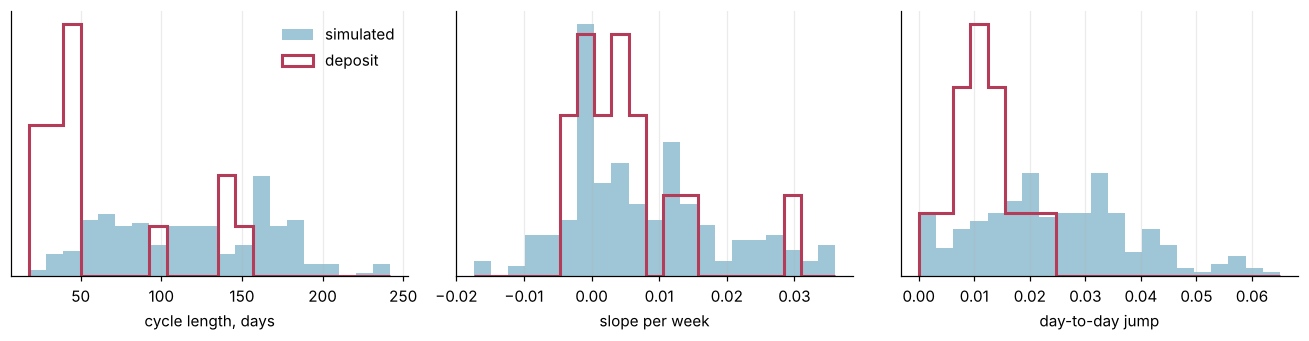

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, k, lab in zip(axes, ("length", "slope", "jump"), ("cycle length, days", "slope per week", "day-to-day jump")):
    s, r = S[k].dropna(), R[k].dropna()
    bins = np.linspace(min(r.min(), s.quantile(0.02)), max(r.max(), s.quantile(0.98)), 22)
    ax.hist(s, bins=bins, density=True, color="#9fc6d6", label="simulated")
    ax.hist(r, bins=bins, density=True, histtype="step", lw=2, color="#b53c58", label="deposit")
    ax.set_xlabel(lab); ax.set_yticks([])
axes[0].legend(frameon=False); plt.tight_layout(); plt.show()

**Said plainly:** the simulated cycles are about **2.8× longer** and **2.2× noisier** from day to
day than the real ones. The fouling rates were set after looking at the deposit's slopes; lengths
and noise were not matched before the forecast settings were frozen. So the development and test
results describe a harder, longer-cycle world. `step7_matched_simulator.py` re-runs the key
comparisons in a quieter variant — and one conclusion does not survive it (VALIDATION.md,
section 13).

## What this notebook settled

- The simulator gives what no real plant can: **the crossing day without the cleaning**.
- Its operator reads the screen, so cleanings depend on the very signal being forecast — as in a
  real plant.
- It is **noisier, with longer cycles,** than the one real plant we have — a known limit.

Next: [04 · The forecast, its range and its flag](04_forecast.ipynb).